# Лабораторная работа №4
## CTC с нуля

**Выполнила:** Перминова Анастасия, группа M4221

Дополненные функции:

| Функция | Что получает | Что возвращает |
|---|---|---|
| `merge_then_remove(path, blank)` | путь (список символов по кадрам) и символ blank | соседние повторы объединены, blank удалены |
| `sum_matching(records, target)` | записи полного перебора путей и целевую строку | сумму вероятностей всех путей, которые сворачиваются в `target` |
| `incoming_sum(previous, extended, state, blank)` | строку таблицы alpha для предыдущего кадра, расширенную цель, номер состояния, blank | сумму переходов в состояние `state` (без умножения на эмиссию текущего кадра) |
| `terminal_sum(last_row)` | последнюю строку таблицы alpha | вероятность всей транскрипции (сумма двух терминальных ячеек или единственная ячейка) |
| `greedy_path(emissions, alphabet)` | эмиссии по кадрам и алфавит | путь, в котором в каждом кадре выбран символ с максимальной вероятностью |
| `prefix_transitions(prefix, p_blank, p_nonblank, symbol, probability)` | префикс, две накопленные массы (на blank/не blank), символ и его вероятность в кадре | список пар `(новый префикс, масса)`, оканчивающихся на непустой символ |

```python
def merge_then_remove(path, blank):
    merged = []
    for symbol in path:
        if not merged or merged[-1] != symbol:
            merged.append(symbol)
    return ''.join(symbol for symbol in merged if symbol != blank)
```

```python
def sum_matching(records, target):
    return math.fsum(r['probability'] for r in records if r['transcript'] == target)
```

Порядок: сначала объединяем соседние одинаковые символы, и только потом удаляем blank. Поэтому `b b` дает `b`, а `b blank b` дает `bb`: blank между двумя `b` не дает им слиться, и повтор буквы сохраняется. Если сначала удалить blank, то `b blank b` превратится в `b b` и затем в `b`, то есть повтор потеряется.

`sum_matching` складывает вероятности всех записей, у которых свернутая транскрипция равна `target`.

In [33]:
import csv
import json
import math
import subprocess
import sys
from pathlib import Path

from IPython.display import SVG, display

LAB_ROOT = Path.cwd()
sys.path.insert(0, str(LAB_ROOT))

subprocess.run([sys.executable, str(LAB_ROOT / "scripts" / "run_lab_04.py"), "--output-dir", str(LAB_ROOT / "outputs")], check=True)
summary = json.loads((LAB_ROOT / "outputs" / "summary.json").read_text(encoding="utf-8"))
summary

{'fixtures': ['forward.json', 'decoding.json', 'repeated.json'],
 'target': 'ba',
 'repeated_target': 'bb',
 'path_count': 27,
 'matching_path_count': 5,
 'transcript_probability': 0.661,
 'final_alpha_cells': [0.581, 0.08000000000000002],
 'greedy_path': ['a', 'blank', 'blank'],
 'greedy_transcript': 'a',
 'beam_width': 5,
 'beam_best': 'ab',
 'beam_ledger': [['ab', 0.3115],
  ['a', 0.22150000000000003],
  ['b', 0.1885],
  ['ba', 0.094],
  ['aa', 0.054000000000000006]]}

**Свертка путей и полный перебор**

Алфавит `[blank, b, a]`, цель `ba`, три кадра. Это синтетические вероятности.

In [34]:
fx = {n: json.loads((LAB_ROOT / "data" / f"{n}.json").read_text(encoding="utf-8")) for n in ("forward", "decoding", "repeated")}
fw = fx["forward"]

print("Алфавит:", fw["alphabet"], "| цель:", fw["target"], "| кадров:", len(fw["emissions"]))
print()
print(f"{'кадр':<6}" + "".join(f"{s:>8}" for s in fw["alphabet"]))
for i, row in enumerate(fw["emissions"], 1):
    print(f"f{i:<5}" + "".join(f"{row[s]:>8.2f}" for s in fw["alphabet"]))

Алфавит: ['blank', 'b', 'a'] | цель: ba | кадров: 3

кадр     blank       b       a
f1        0.10    0.80    0.10
f2        0.20    0.30    0.50
f3        0.20    0.10    0.70


Сначала проверим свертку:

In [35]:
from scripts.ctc_core import collapse_path, enumerate_paths, sum_transcript_probability

examples = [["b", "b"], ["b", "blank", "b"], ["blank", "b", "b", "blank", "a", "a"], []]
for p in examples:
    shown = " ".join(p) if p else "(пустой путь)"
    print(f"{shown:<28} →  {collapse_path(p)!r}")

b b                          →  'b'
b blank b                    →  'bb'
blank b b blank a a          →  'ba'
(пустой путь)                →  ''


`b b` дает `b`, а `b blank b` дает `bb`. Дальше перебираем все пути: алфавит из 3 символов и 3 кадра дают 3³ = 27 путей. Вероятность пути равна произведению вероятностей символов по кадрам.

In [36]:
records = enumerate_paths(fw["emissions"], fw["alphabet"], fw["blank"])
matching = [r for r in records if r["transcript"] == fw["target"]]

print("Всего путей:", len(records))
print(f"Путей, которые сворачиваются в {fw['target']!r}:", len(matching))
print()
for r in matching:
    print(f"{' '.join(r['path']):<16} p = {r['probability']:.3f}")

total = sum_transcript_probability(records, fw["target"])
print()
print("Сумма по этим путям:", round(total, 6))
print("Сумма по всем 27 путям:", round(sum(r["probability"] for r in records), 6))

Всего путей: 27
Путей, которые сворачиваются в 'ba': 5

blank b a        p = 0.021
b blank a        p = 0.112
b b a            p = 0.168
b a blank        p = 0.080
b a a            p = 0.280

Сумма по этим путям: 0.661
Сумма по всем 27 путям: 1.0


Из 27 путей в `ba` сворачиваются 5. Сумма их вероятностей равна **0.661**. Сумма по всем 27 путям равна 1, потому что в каждом кадре вероятности образуют распределение - значит, перебор выполнен полностью.

**Прямой проход (forward)**
```python
def incoming_sum(previous, extended, state, blank):
    total = previous[state]                      # остались в том же состоянии
    if state >= 1:
        total += previous[state - 1]             # переход из s-1
    if state >= 2 and extended[state] != blank and extended[state] != extended[state - 2]:
        total += previous[state - 2]             # пропуск из s-2
    return total
```

```python
def terminal_sum(last_row):
    if len(last_row) == 1:                       # пустая цель: только blank
        return last_row[0]
    return last_row[-1] + last_row[-2]
```

Цель расширяется blank'ами с обоих краев и между символами: `ba` превращается в `[blank, b, blank, a, blank]`. Путь в этой цепочке состояний может в каждом кадре остаться на месте, перейти на следующее состояние или (при определенных условиях) перепрыгнуть через одно. Поэтому `incoming_sum` складывает до трех слагаемых:

- `previous[state]`: остались в том же состоянии;
- `previous[state - 1]`: пришли из соседнего слева, если он существует;
- `previous[state - 2]`: пропустили одно состояние. Это разрешено, только если текущее состояние не blank (пропуск blank'а ничего не дает) и отличается от `extended[state - 2]`. Для одинаковых символов (`bb`) пропуск запрещен: без blank между ними путь `b b` свернулся бы в один `b`.

Умножение на эмиссию текущего кадра выполняется снаружи, в `forward_table`.

`terminal_sum`: расшифровка заканчивается либо на последнем символе цели, либо на финальном blank, поэтому берем две последние ячейки. Для пустой цели расширенная цель состоит из одного blank, и берется единственная ячейка.

In [37]:
from scripts.ctc_forward import extended_target, forward_table, transcript_probability

states = extended_target(fw["target"], fw["blank"])
table = forward_table(fw["emissions"], fw["target"], fw["blank"])
labels = [f"{i}:{s}" for i, s in enumerate(states)]

print("Расширенная цель:", states)
print()
print(f"{'кадр':<6}" + "".join(f"{l:>10}" for l in labels))
for t, row in enumerate(table, 1):
    print(f"f{t:<5}" + "".join(f"{v:>10.3f}" for v in row))

last = table[-1]
print()
print(f"Терминальные ячейки alpha: [3:a] = {last[-2]:.3f}, [4:blank] = {last[-1]:.3f}")
print("Их сумма:                  ", round(transcript_probability(table), 6))
print("Сумма по путям (часть A):  ", round(total, 6))

Расширенная цель: ['blank', 'b', 'blank', 'a', 'blank']

кадр     0:blank       1:b   2:blank       3:a   4:blank
f1         0.100     0.800     0.000     0.000     0.000
f2         0.020     0.270     0.160     0.400     0.000
f3         0.004     0.029     0.086     0.581     0.080

Терминальные ячейки alpha: [3:a] = 0.581, [4:blank] = 0.080
Их сумма:                   0.661
Сумма по путям (часть A):   0.661


Таблица alpha заполняется кадр за кадром: в первом кадре ненулевые только состояния 0 (blank) и 1 (`b`), потому что путь должен начаться либо с blank, либо с первого символа цели. Терминальные ячейки в последнем кадре: состояние `a` равно **0.581**, финальный blank равен **0.080**. Их сумма **0.661** совпадает с суммой по 5 путям из части A. Прямой проход считает то же самое, но не перебирает пути, а переиспользует промежуточные суммы: вместо 3^T путей ему нужно где-то T · |S| ячеек.

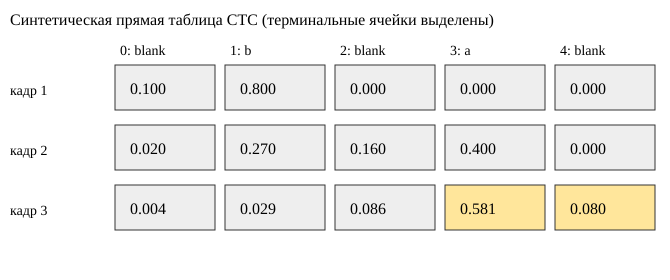

In [38]:
display(SVG(filename=str(LAB_ROOT / "outputs" / "forward_table.svg")))

Проверим запрет пропуска на отдельном наборе `repeated.json`: алфавит `[blank, b]`, цель `bb`, во всех кадрах вероятности по 0.5.

In [39]:
rp = fx["repeated"]
rows3 = rp["emissions"]

print("bb, 2 кадра:", transcript_probability(forward_table(rows3[:2], "bb", rp["blank"])))
print("bb, 3 кадра:", transcript_probability(forward_table(rows3, "bb", rp["blank"])))

bb, 2 кадра: 0.0
bb, 3 кадра: 0.125


Между двумя `b` нужен хотя бы один blank, поэтому в двух кадрах `bb` получить нельзя (вероятность 0), а в трех есть единственный путь `b blank b` с вероятностью 0.5³ = 0.125. Если бы пропуск `s-2` между одинаковыми символами был разрешен, прямой проход нашел бы путь `b b` и дал бы ненулевую вероятность в двух кадрах, хотя `b b` сворачивается в одиночный `b`.

**Жадный поиск и префиксный луч**
```python
def greedy_path(emissions, alphabet):
    path = []
    for row in emissions:
        best = alphabet[0]
        for symbol in alphabet[1:]:
            if row[symbol] > row[best]:          # при равенстве остается ранний по алфавиту
                best = symbol
        path.append(best)
    return path
```

```python
def prefix_transitions(prefix, p_blank, p_nonblank, symbol, probability):
    extended = prefix + symbol
    if prefix and prefix[-1] == symbol:
        # повтор: без blank остаемся в том же префиксе, через blank расширяем
        return [
            (prefix, p_nonblank * probability),
            (extended, p_blank * probability),
        ]
    return [(extended, (p_blank + p_nonblank) * probability)]
```

**Жадный поиск.** В каждом кадре берется символ с максимальной вероятностью. Условие `>` строгое, поэтому при равенстве оставляем символ, который раньше по алфавиту. Затем путь сворачивается функцией `collapse_path`.

**Префиксный луч.** Для каждого префикса хранятся две массы: `p_blank` (пути, оканчивающиеся на blank) и `p_nonblank` (оканчивающиеся на символ). Они нужны, чтобы правильно обработать повторы. Для нового символа `symbol`:

если последний символ префикса не равен `symbol`, любая накопленная масса (`p_blank + p_nonblank`) расширяет префикс: `префикс → префикс + symbol`; если равен, то между двумя одинаковыми символами нужен blank. Поэтому расширяет префикс только `p_blank`, а `p_nonblank` остается у того же префикса (повторяющийся символ склеивается с предыдущим и ничего не добавляет).

Сам цикл луча складывает все пришедшие массы одного префикса до отсечения, а затем оставляет `beam_width` лучших. Поэтому в луче получается сумма по путям, а не один путь.

In [40]:
from scripts.ctc_decode import greedy_decode, prefix_beam_decode, prefix_transitions

dc = fx["decoding"]
print("Эмиссии:")
print(f"{'кадр':<6}" + "".join(f"{s:>8}" for s in dc["alphabet"]))
for i, row in enumerate(dc["emissions"], 1):
    print(f"f{i:<5}" + "".join(f"{row[s]:>8.2f}" for s in dc["alphabet"]))

path, text = greedy_decode(dc["emissions"], dc["alphabet"], dc["blank"])
path_p = math.prod(row[s] for row, s in zip(dc["emissions"], path))
print()
print("Жадный путь:", path, "→", repr(text))
print("Вероятность этого пути:", round(path_p, 4))

Эмиссии:
кадр     blank       a       b
f1        0.10    0.60    0.30
f2        0.45    0.20    0.35
f3        0.45    0.20    0.35

Жадный путь: ['a', 'blank', 'blank'] → 'a'
Вероятность этого пути: 0.1215


In [42]:
best, ledger = prefix_beam_decode(dc["emissions"], dc["alphabet"], dc["beam_width"], dc["blank"])

dec_records = enumerate_paths(dc["emissions"], dc["alphabet"], dc["blank"])
exact = {}
for r in dec_records:
    exact[r["transcript"]] = exact.get(r["transcript"], 0.0) + r["probability"]

print(f"Луч ширины {dc['beam_width']} → {best!r}")
print()
print(f"{'префикс':<10}{'масса в луче':>14}{'точная масса':>14}")
for prefix, mass in ledger:
    print(f"{prefix:<10}{mass:>14.4f}{exact[prefix]:>14.4f}")

kept = sum(mass for _, mass in ledger)
print()
print("Масса, сохраненная в луче:", round(kept, 4), "из 1.0")
print("Масса отсеченных префиксов:", round(1 - kept, 4))

Луч ширины 5 → 'ab'

префикс     масса в луче  точная масса
ab                0.3115        0.3115
a                 0.2215        0.2215
b                 0.1885        0.1885
ba                0.0940        0.0940
aa                0.0540        0.0540

Масса, сохраненная в луче: 0.8695 из 1.0
Масса отсеченных префиксов: 0.1305


Столбцы «масса в луче» и «точная масса» совпали. Здесь отсечение происходит только на последнем кадре (до него кандидатов не больше пяти), поэтому ни один путь не потерян. При узком луче или длинной записи префикс мог бы потерять часть массы из-за путей через префиксы, отброшенные раньше: масса в луче могла бы оказаться меньше точной, потому что пути через отброшенные префиксы не учитываются (приближенность луча).

Жадный метод дает путь `a blank blank` и расшифровку **`a`**. Луч ширины 5 дает **`ab`**. Посмотрим на все пути, которые сворачиваются в `ab` и в `a`.

In [43]:
for name in ("ab", "a"):
    group = sorted((r for r in dec_records if r["transcript"] == name), key=lambda r: -r["probability"])
    print(f"Пути для {name!r}:")
    for r in group:
        print(f"  {' '.join(r['path']):<16} p = {r['probability']:.4f}")
    print(f"  сумма = {sum(r['probability'] for r in group):.4f}")
    print()

print("Самый вероятный путь вообще:", max(dec_records, key=lambda r: r["probability"])["path"])

Пути для 'ab':
  a blank b        p = 0.0945
  a b blank        p = 0.0945
  a b b            p = 0.0735
  a a b            p = 0.0420
  blank a b        p = 0.0070
  сумма = 0.3115

Пути для 'a':
  a blank blank    p = 0.1215
  a a blank        p = 0.0540
  a a a            p = 0.0240
  blank a blank    p = 0.0090
  blank blank a    p = 0.0090
  blank a a        p = 0.0040
  сумма = 0.2215

Самый вероятный путь вообще: ['a', 'blank', 'blank']


У `a` самый вероятный путь `a blank blank` (0.1215), и он же выбирается жадным методом. У `ab` пять путей, ни один из которых не превосходит 0.0945, но вместе они дают **0.3115**, а все пути `a` вместе дают только **0.2215**. Жадный метод ищет самый вероятный путь, а нас интересует самая вероятная транскрипция, то есть сумма по всем путям, которые в нее сворачиваются. Префиксный луч считает именно эту сумму.

Проверка `prefix_transitions` на примере с повтором:

In [44]:
print(prefix_transitions("a", 0.2, 0.3, "a", 0.5))
print(prefix_transitions("a", 0.2, 0.3, "b", 0.5))

[('a', 0.15), ('aa', 0.1)]
[('ab', 0.25)]


В первом случае `('a', 0.15)`: масса `0.3 · 0.5` осталась у префикса `a`, и `('aa', 0.1)`: масса `0.2 · 0.5` ушла в `aa`, потому что путь, оканчивающийся на blank, может начать новый `a`. Во втором случае обе массы суммируются: `(0.2 + 0.3) · 0.5 = 0.25`.

## Вопросы

**1. Укажите число путей для `ba`, их сумму и обе терминальные ячейки alpha.**

- Всего путей 3³ = 27, подходящих (сворачиваются в `ba`) 5: `b a blank`, `b blank a`, `blank b a`, `b b a`, `b a a`.
- Сумма их вероятностей 0.661.
- Терминальные ячейки alpha в последнем кадре: состояние `3:a` равно 0.581, состояние `4:blank` равно 0.080. Их сумма 0.661 совпадает с суммой по путям.

**2. Приведите выходы жадного алгоритма и луча с шириной 5. В чём различие между одним путём и суммарной массой транскрипции?**

- Жадный метод: путь `a blank blank`, транскрипция `a`. Вероятность этого пути 0.1215.
- Луч ширины 5: `ab` с массой 0.3115; следом `a` (0.2215), `b` (0.1885), `ba` (0.094), `aa` (0.054).
- Один путь - это конкретная последовательность символов по кадрам. У одной транскрипции таких путей может быть много (`ab` получается как `a b blank`, `a blank b`, `a b b`, `a a b`, `blank a b`). Масса транскрипции - сумма вероятностей всех ее путей. Самый вероятный путь не обязан принадлежать самой вероятной транскрипции: здесь лучший путь ведет в `a`, но суммарно побеждает `ab`.

**3. Назовите ограничения синтетических входных данных, отсечения луча или вычислений в пространстве вероятностей и предложите варианты развития представленного подхода.**

**Синтетические данные.** Вероятности в данной лабораторнойсозданы вручную: всего 3 кадра и 2–3 символа. Реальная акустическая модель выдает сотни кадров и десятки символов, поэтому на таком примере нельзя оценить, как алгоритмы поведут себя на настоящих записях. Полный перебор путей тоже применим только для таких маленьких примеров: число путей растет как |алфавит|^T, у нас стоит лимит в 10000 путей.

**Отсечение луча.** Луч хранит только `beam_width` лучших префиксов, а остальные выбрасывает. Если префикс отброшен рано, его уже не вернуть, хотя в дальнейшем он мог бы стать лучшим. Поэтому массы в луче приближенные, и результат зависит от ширины луча. Если ширина достаточно большая, ничего не отбрасывается, и луч совпадает с полным перебором.

**Вычисления в пространстве вероятностей.** Мы перемножаем вероятности кадров. Для 200 кадров по 0.01 произведение равно 10⁻⁴⁰⁰, оно округляется до нуля (underflow). На длинных записях все вероятности превратились бы в нули. Можно было бы считать не сами вероятности, а их логарифмы. Тогда произведения стали бы суммами.

**Что можно улучшить:**

- перейти на логарифмы, чтобы работать с длинными записями;
- добавить в луч языковую модель;
- отбрасывать префиксы не только по ширине луча, но и по порогу массы;
- считать сразу по нескольким записям и векторизовать вычисления;
- проверить на реальных выходах акустической модели.